### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 10

### Actor-Critic Reinforcement Learning for Elevator Control

### Name: Yashvanth Karunakaran (23BAI1589)

### AIM:
To implement an Actor-Critic agent that controls an elevator, choosing a direction, speed and duration, with the objective of minimising passenger waiting time.

Github Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-10.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-10.ipynb)

#### Installing Dependencies

In [14]:
%pip install -q gymnasium numpy matplotlib torch pandas

/home/yashix/.zshenv:.:1: no such file or directory: /home/yashix/.cargo/env
/media/yashix/New Volume/Stockify/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


#### Elevator Environment
State Space:

$$
s_t = [\text{floor},\ \text{speed},\ \text{door timing},\ \text{average wait},\ \text{passenger count}]
$$

Action Space:

- Discrete action: move down, stay, or move up.
- Continuous action: adjust the elevator speed and door timing.

Reward:

$$
r_t = \text{service reward} - 0.05 \times \text{waiting time}
$$

service reward is 1 when the elevator reaches a passenger's source floor and 2 when it reaches the passenger's destination floor. serving passengers increases the reward, while long waiting times reduce it.

discounted return:

$$
G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \cdots
$$

$\gamma = 0.99$

advantage measurement:

$$
A_t = G_t - V(s_t)
$$

actor is trained using the policy loss, while critic use value loss:

$$
L_{policy} = -\log \pi(a_t|s_t) A_t
$$

$$
L_{value} = \left(V(s_t) - G_t\right)^2
$$

final loss has both parts:

$$
L = L_{policy} + 0.5L_{value}
$$

In [15]:
import numpy as np

class ElevatorEnvironment:
    def __init__(self, num_floors=10):
        self.num_floors = num_floors
        self.reset()
        
    def reset(self):
        self.current_floor = np.random.randint(0, self.num_floors)
        self.speed = 1.0
        self.door_timing = 3.0
        self.passengers = []
        for _ in range(5):
            s = np.random.randint(0, self.num_floors)
            d = np.random.randint(0, self.num_floors)
            while d == s:
                d = np.random.randint(0, self.num_floors)
            self.passengers.append({'source': s, 'dest': d, 'wait': 0.0})
        return self._get_state()
        
    def _get_state(self):
        avg_wait = np.mean([p['wait'] for p in self.passengers]) if self.passengers else 0.0
        return np.array([
            self.current_floor / float(self.num_floors - 1),
            self.speed / 2.0,
            self.door_timing / 5.0,
            avg_wait / 20.0,
            len(self.passengers) / 10.0
        ], dtype=np.float32)
        
    def step(self, action_discrete, action_continuous):
        # action_discrete: 0 (Down), 1 (Stay), 2 (Up)
        # action_continuous: [speed_delta, timing_delta]
        
        speed_change, timing_change = action_continuous
        self.speed = np.clip(self.speed + speed_change * 0.1, 0.5, 2.0)
        self.door_timing = np.clip(self.door_timing + timing_change * 0.2, 1.0, 5.0)
        
        if action_discrete == 2 and self.current_floor < self.num_floors - 1:
            self.current_floor += 1
        elif action_discrete == 0 and self.current_floor > 0:
            self.current_floor -= 1
            
        reward = 0.0
        remaining_passengers = []
        for p in self.passengers:
            p['wait'] += self.speed
            if p['source'] == self.current_floor:
                reward += 1.0
            elif p['dest'] == self.current_floor:
                reward += 2.0
                p['wait'] = max(0, p['wait'] - 5.0)
            
            reward -= 0.05 * p['wait'] # Penalty for passenger waiting time
            if p['wait'] < 30.0:
                remaining_passengers.append(p)
                
        if np.random.rand() < 0.4:
            s = np.random.randint(0, self.num_floors)
            d = np.random.randint(0, self.num_floors)
            if d != s:
                remaining_passengers.append({'source': s, 'dest': d, 'wait': 0.0})
                
        self.passengers = remaining_passengers
        done = len(self.passengers) > 15
        return self._get_state(), reward, done

#### Build the Actor-Critic Model

actor chooses the elevator direction, speed adjustment, and door-timing adjustment and the critic estimates how useful the current state is

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical, Normal

class ActorCritic(nn.Module):
    def __init__(self, state_dim=5):
        super(ActorCritic, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )
        self.discrete_head = nn.Linear(64, 3)
        self.cont_mean = nn.Linear(64, 2)
        self.cont_std = nn.Linear(64, 2)
        self.critic = nn.Linear(64, 1)
        
    def forward(self, state):
        features = self.fc(state)
        
        # discrete distribution (Up, Stay, Down)
        logits = self.discrete_head(features)
        dist_discrete = Categorical(logits=logits)
        
        # continuous distribution (speed and timing adjustments)
        mean = self.cont_mean(features)
        std = F.softplus(self.cont_std(features)) + 1e-5
        dist_cont = Normal(mean, std)
        
        value = self.critic(features)
        return dist_discrete, dist_cont, value

#### Train the Agent

For each episode, the agent observes the state, samples an action, receives a reward, and moves to the next state. After the episode ends, the return and advantage are calculated, optimizer then updates the actor and critic so that useful actions become more likely

In [17]:
import torch.optim as optim

env = ElevatorEnvironment(num_floors=10)
model = ActorCritic()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_episodes = 200
gamma = 0.99
training_rewards = []

for episode in range(num_episodes):
    state = torch.FloatTensor(env.reset())
    log_probs, values, rewards = [], [], []
    
    done = False
    while not done:
        dist_discrete, dist_cont, value = model(state)
        
        action_d = dist_discrete.sample()
        action_c = dist_cont.sample()
        
        log_prob_d = dist_discrete.log_prob(action_d)
        log_prob_c = dist_cont.log_prob(action_c).sum(dim=-1)
        total_log_prob = log_prob_d + log_prob_c
        
        next_state, reward, done = env.step(action_d.item(), action_c.detach().numpy())
        
        log_probs.append(total_log_prob)
        values.append(value)
        rewards.append(reward)
        
        state = torch.FloatTensor(next_state)
        if done:
            break
            
    returns, G = [], 0
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
        
    returns = torch.FloatTensor(returns)
    values = torch.cat(values)
    advantages = returns - values.detach()
    
    policy_loss, value_loss = [], []
    for log_p, adv, ret, val in zip(log_probs, advantages, returns, values):
        policy_loss.append(-log_p * adv)
        value_loss.append((val - ret) ** 2)
        
    optimizer.zero_grad()
    loss = torch.stack(policy_loss).mean() + 0.5 * torch.stack(value_loss).mean()
    loss.backward()
    optimizer.step()
    
    episode_reward = sum(rewards)
    training_rewards.append(episode_reward)
    if (episode + 1) % 20 == 0:
        print(f"Episode {episode + 1}/{num_episodes} | Total Reward: {episode_reward:.2f}")

Episode 20/200 | Total Reward: -165.49
Episode 40/200 | Total Reward: -121.11
Episode 60/200 | Total Reward: -192.76
Episode 80/200 | Total Reward: 92.80
Episode 100/200 | Total Reward: 83.71
Episode 120/200 | Total Reward: -4.43
Episode 140/200 | Total Reward: 86.47
Episode 160/200 | Total Reward: -33.30
Episode 180/200 | Total Reward: 19.72
Episode 200/200 | Total Reward: -4.56


#### Policy Evaluation

function to test either the random or trained policy.

In [18]:
import matplotlib.pyplot as plt


def evaluate_policy(policy, episodes=100):
    episode_rewards = []
    
    for _ in range(episodes):
        eval_env = ElevatorEnvironment(num_floors=10)
        state = eval_env.reset()
        total_reward = 0.0
        done = False
        
        while not done:
            if policy == "random":
                action_d = np.random.randint(0, 3)
                action_c = np.random.uniform(-1.0, 1.0, size=2)
            else:
                with torch.no_grad():
                    state_tensor = torch.FloatTensor(state)
                    dist_discrete, dist_cont, _ = model(state_tensor)
                    action_d = dist_discrete.sample().item()
                    action_c = dist_cont.sample().numpy()
            
            state, reward, done = eval_env.step(action_d, action_c)
            total_reward += reward
        
        episode_rewards.append(total_reward)
    
    return np.array(episode_rewards)

#### Compare Random and Actor-Critic Policies

In [19]:
comparison_episodes = 100

random_rewards = evaluate_policy("random", comparison_episodes)
actor_critic_rewards = evaluate_policy("actor_critic", comparison_episodes)

#### Prepare the Reward Data

calculate moving averages to make the reward trends so it is easier to read

In [20]:
window = 10

training_moving_average = np.convolve(
    training_rewards,
    np.ones(window) / window,
    mode="valid",
)
random_moving_average = np.convolve(
    random_rewards,
    np.ones(window) / window,
    mode="valid",
)
actor_critic_moving_average = np.convolve(
    actor_critic_rewards,
    np.ones(window) / window,
    mode="valid",
)

#### Plot the Reward Comparison

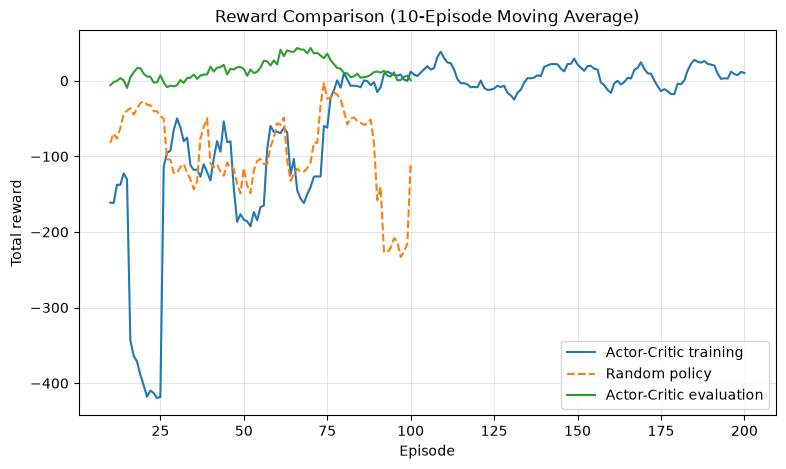

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(window, len(training_rewards) + 1),
    training_moving_average,
    label="Actor-Critic training",
)
plt.plot(
    np.arange(window, comparison_episodes + 1),
    random_moving_average,
    label="Random policy",
    linestyle="--",
)
plt.plot(
    np.arange(window, comparison_episodes + 1),
    actor_critic_moving_average,
    label="Actor-Critic evaluation",
)

plt.title("Reward Comparison (10-Episode Moving Average)")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Plot the Reward Distribution

Use a boxplot to compare the final reward distributions

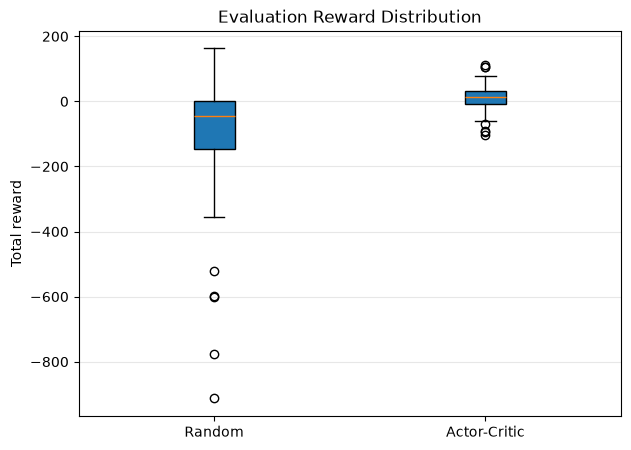

Random policy: mean = -92.60319807767591, std = 166.96730661154737
Actor-Critic policy: mean = 12.05212116241455, std = 41.4091796875


In [22]:
plt.figure(figsize=(7, 5))
plt.boxplot(
    [random_rewards, actor_critic_rewards],
    tick_labels=["Random", "Actor-Critic"],
    patch_artist=True,
),
plt.title("Evaluation Reward Distribution")
plt.ylabel("Total reward")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"Random policy: mean = {random_rewards.mean()}, std = {random_rewards.std()}")
print(f"Actor-Critic policy: mean = {actor_critic_rewards.mean()}, std = {actor_critic_rewards.std()}")

#### Conclusion

In this evaluation, Actor-Critic performed better than the random policy. Actor-Critic achieved a higher average reward than random policy (16.84 vs -104.49) with less variation, showing more consistent elevator control